# PUSL 3205 - Large Language Models and Generative AI
## Lab: Sentiment Analysis Using Traditional Machine Learning

**Objective:** Practice basic NLP tasks  
**Topic:** Text Preprocessing, TF-IDF and Machine Learning  
**Libraries:** Pandas, NumPy, NLTK, Scikit-learn, Matplotlib, Seaborn  
**Dataset:** [UCI Sentiment Labelled Sentences](https://archive.ics.uci.edu/dataset/331/sentiment%2Blabelled%2Bsentences)

**Student Name:** _your name_  
**Student ID:** _your ID_

In [1]:
import re
import io
import os
import zipfile
import urllib.request
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)

nltk.download('stopwords', quiet=True)
sns.set_theme(style='whitegrid')
pd.set_option('display.max_colwidth', 100)

## Task 1: Download and load the dataset
The dataset has three files (Amazon, IMDB, Yelp). Each line is `sentence <TAB> label` where 1 = positive and 0 = negative. We combine them into one DataFrame.

In [2]:
URL = 'https://archive.ics.uci.edu/static/public/331/sentiment+labelled+sentences.zip'
DATA_DIR = 'sentiment labelled sentences'

if not os.path.isdir(DATA_DIR):
    print('Downloading dataset...')
    data = urllib.request.urlopen(URL).read()
    with zipfile.ZipFile(io.BytesIO(data)) as z:
        z.extractall('.')
    print('Done.')

files = {'amazon': 'amazon_cells_labelled.txt',
         'imdb': 'imdb_labelled.txt',
         'yelp': 'yelp_labelled.txt'}

frames = []
for source, fname in files.items():
    part = pd.read_csv(os.path.join(DATA_DIR, fname), sep='\t',
                       header=None, names=['text', 'label'])
    part['source'] = source
    frames.append(part)

df = pd.concat(frames, ignore_index=True)
print('Shape:', df.shape)
df.head()

Done.
Shape: (2748, 3)


,text,label,source
0,So there is no way for me to plug it in here in the US unless I go by a converter.,0,amazon
1,"Good case, Excellent value.",1,amazon
2,Great for the jawbone.,1,amazon
3,Tied to charger for conversations lasting more than 45 minutes.MAJOR PROBLEMS!!,0,amazon
4,The mic is great.,1,amazon


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2748 entries, 0 to 2747
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    2748 non-null   object
 1   label   2748 non-null   int64 
 2   source  2748 non-null   object
dtypes: int64(1), object(2)
memory usage: 64.5+ KB
None

Missing values:
 text      0
label     0
source    0
dtype: int64

Class distribution:
 label
1    1386
0    1362
Name: count, dtype: int64


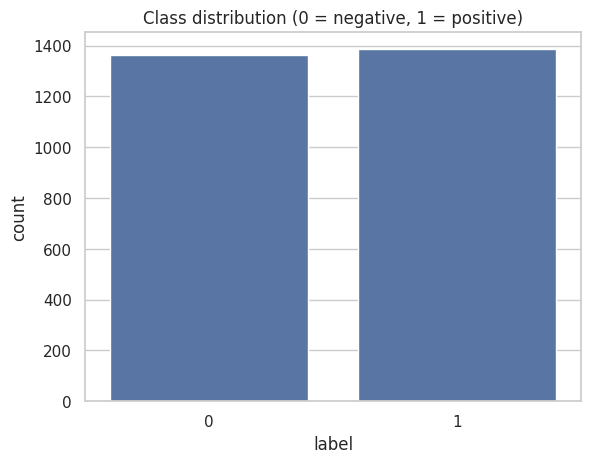

In [3]:
print(df.info())
print()
print('Missing values:\n', df.isnull().sum())
print()
print('Class distribution:\n', df['label'].value_counts())
sns.countplot(data=df, x='label')
plt.title('Class distribution (0 = negative, 1 = positive)')
plt.show()

## Task 2: Basic text preprocessing
Steps: lowercase -> remove unnecessary characters and punctuation -> remove extra whitespace -> store in a `clean_text` column.

In [4]:
def preprocess(text):
    text = str(text).lower()                    # 1. lowercase
    text = re.sub(r'[^a-z\s]', ' ', text)       # 2. remove punctuation, digits, symbols
    text = re.sub(r'\s+', ' ', text).strip()    # 3. remove extra whitespace
    return text

df['clean_text'] = df['text'].apply(preprocess)   # 4. clean-text column
df[['text', 'clean_text']].head()

,text,clean_text
0,So there is no way for me to plug it in here in the US unless I go by a converter.,so there is no way for me to plug it in here in the us unless i go by a converter
1,"Good case, Excellent value.",good case excellent value
2,Great for the jawbone.,great for the jawbone
3,Tied to charger for conversations lasting more than 45 minutes.MAJOR PROBLEMS!!,tied to charger for conversations lasting more than minutes major problems
4,The mic is great.,the mic is great


**Compare original and preprocessed text**

In [5]:
sample = df.sample(8, random_state=1)
for _, row in sample.iterrows():
    print('ORIGINAL :', row['text'])
    print('CLEANED  :', row['clean_text'])
    print('-' * 80)

df['orig_len'] = df['text'].str.len()
df['clean_len'] = df['clean_text'].str.len()
print('Average length - original:', round(df['orig_len'].mean(), 1),
      '| cleaned:', round(df['clean_len'].mean(), 1))

ORIGINAL : I mean this in a terrible way.  
CLEANED  : i mean this in a terrible way
--------------------------------------------------------------------------------
ORIGINAL : Perhaps I caught them on an off night judging by the other reviews, but I'm not inspired to go back.
CLEANED  : perhaps i caught them on an off night judging by the other reviews but i m not inspired to go back
--------------------------------------------------------------------------------
ORIGINAL : Later I found myself lost in the power of the film.  
CLEANED  : later i found myself lost in the power of the film
--------------------------------------------------------------------------------
ORIGINAL : But it is entertaining, nonetheless.  
CLEANED  : but it is entertaining nonetheless
--------------------------------------------------------------------------------
ORIGINAL : IT'S REALLY EASY.
CLEANED  : it s really easy
--------------------------------------------------------------------------------
ORIGINAL

## Task 3: Explore the text data

In [6]:
print('=== POSITIVE examples ===')
for t in df[df['label'] == 1]['text'].sample(5, random_state=42):
    print('+', t)

print('\n=== NEGATIVE examples ===')
for t in df[df['label'] == 0]['text'].sample(5, random_state=42):
    print('-', t)

=== POSITIVE examples ===
+ The original Body and Soul (1947) is a masterpiece.  
+ Better than you'd expect.
+ So we went to Tigerlilly and had a fantastic afternoon!
+ Lovely little thriller from Hitchcock, with lots of nice shenanigans surrounding a murdered spy, a kidnapped child, a nasty church, a foreign plot and some random taxidermists.  
+ Conclusion - I loved it.  

=== NEGATIVE examples ===
- That's a huge design flaw (unless I'm not using it correctly, which I don't think is the case).
- However, my recent experience at this particular location was not so good.
- The ambiance here did not feel like a buffet setting, but more of a douchey indoor garden for tea and biscuits.
- The acting was bad, the dialogs were extremely shallow and insincere.  
- There was hardly any meat.


### Frequently occurring words
We remove English stop words here so the chart shows meaningful words.

In [7]:
stop_words = set(stopwords.words('english'))

def top_words(series, n=15):
    words = ' '.join(series).split()
    words = [w for w in words if w not in stop_words and len(w) > 1]
    return Counter(words).most_common(n)

pos_top = top_words(df[df['label'] == 1]['clean_text'])
neg_top = top_words(df[df['label'] == 0]['clean_text'])
all_top = top_words(df['clean_text'])

print('Overall   :', all_top)
print('Positive  :', pos_top)
print('Negative  :', neg_top)

Overall   : [('good', 231), ('great', 210), ('movie', 182), ('phone', 168), ('film', 163), ('one', 146), ('food', 126), ('like', 125), ('place', 114), ('time', 112), ('service', 108), ('bad', 103), ('really', 103), ('well', 92), ('would', 87)]
Positive  : [('great', 193), ('good', 174), ('film', 91), ('phone', 88), ('movie', 87), ('one', 68), ('well', 65), ('really', 60), ('food', 60), ('best', 59), ('like', 58), ('place', 58), ('service', 55), ('love', 51), ('time', 50)]
Negative  : [('bad', 96), ('movie', 95), ('phone', 80), ('one', 78), ('film', 72), ('like', 67), ('food', 66), ('time', 62), ('would', 59), ('good', 57), ('place', 56), ('service', 53), ('even', 49), ('back', 48), ('ever', 48)]


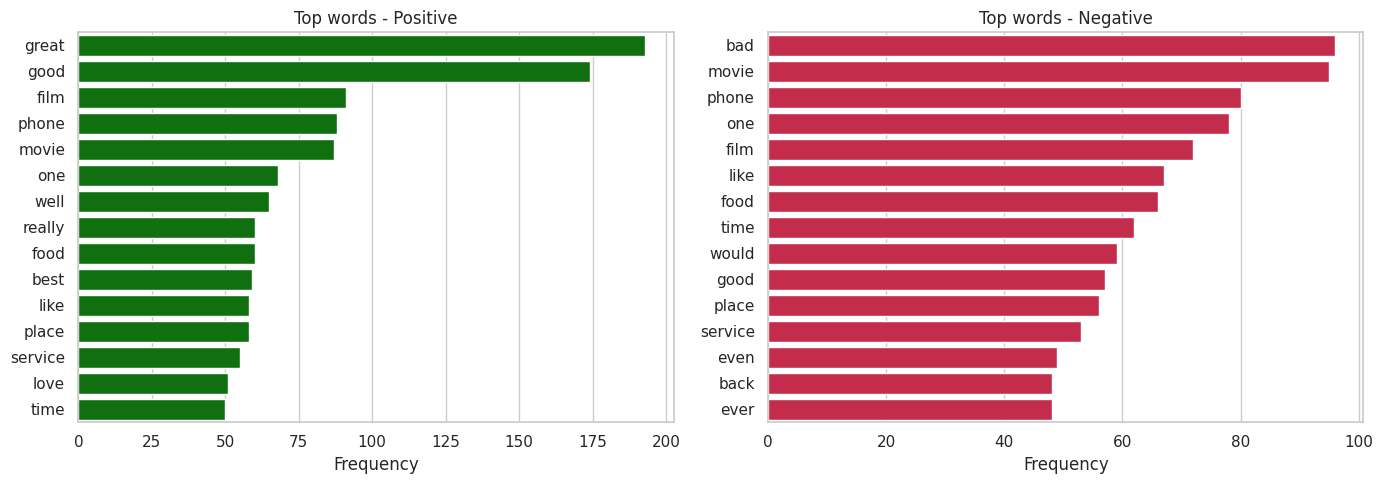

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, data, title, color in zip(axes, [pos_top, neg_top],
                                  ['Top words - Positive', 'Top words - Negative'],
                                  ['green', 'crimson']):
    words, counts = zip(*data)
    sns.barplot(x=list(counts), y=list(words), ax=ax, color=color)
    ax.set_title(title)
    ax.set_xlabel('Frequency')
plt.tight_layout()
plt.show()

### Differences between positive and negative reviews

        count       mean        std  min  25%   50%   75%     max
label                                                            
0      1362.0  13.772394  43.090386  1.0  6.0  11.0  17.0  1319.0
1      1386.0  12.535354  22.366310  0.0  5.0  10.0  16.0   763.0


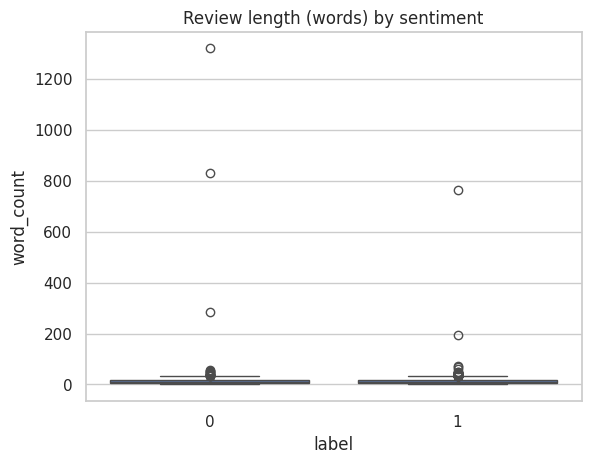


Most negative-leaning words: [('bad', -89), ('worst', -38), ('would', -31), ('waste', -31), ('money', -29), ('terrible', -28), ('poor', -27), ('minutes', -25), ('work', -24), ('never', -24)]
Most positive-leaning words: [('great', 176), ('good', 117), ('nice', 45), ('works', 45), ('love', 41), ('excellent', 41), ('best', 40), ('well', 38), ('price', 24), ('amazing', 24)]


In [9]:
df['word_count'] = df['clean_text'].str.split().str.len()
print(df.groupby('label')['word_count'].describe())

sns.boxplot(data=df, x='label', y='word_count')
plt.title('Review length (words) by sentiment')
plt.show()

# Words most associated with each class (difference in frequency)
pos_c = Counter(w for w in ' '.join(df[df.label == 1]['clean_text']).split() if w not in stop_words)
neg_c = Counter(w for w in ' '.join(df[df.label == 0]['clean_text']).split() if w not in stop_words)
diff = {w: pos_c[w] - neg_c[w] for w in set(pos_c) | set(neg_c)}
ranked = sorted(diff.items(), key=lambda x: x[1])
print('\nMost negative-leaning words:', ranked[:10])
print('Most positive-leaning words:', ranked[-10:][::-1])

**Observations** *(check against your own output and edit if needed)*:
- Positive reviews tend to contain words such as *great, good, love, best, excellent, nice*.
- Negative reviews tend to contain words such as *bad, poor, disappointed, never, waste, worst* and negations like *not*.
- Both classes have a similar balance (about 500 positive and 500 negative per source), so accuracy is a fair metric.
- Review lengths are broadly similar, so sentiment is carried mostly by word choice rather than length.

## Task 4: Split the dataset
80% training / 20% testing, stratified so both sets keep the same class balance.

In [10]:
X = df['clean_text']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print('Training samples:', len(X_train))
print('Testing samples :', len(X_test))
print('Train class balance:\n', y_train.value_counts(normalize=True))

Training samples: 2198
Testing samples : 550
Train class balance:
 label
1    0.50455
0    0.49545
Name: proportion, dtype: float64


## Task 5: Create Bag-of-Words (BOW) representation
The vectorizer is fitted on the **training data only** to avoid data leakage.

In [11]:
bow = CountVectorizer()
X_train_bow = bow.fit_transform(X_train)
X_test_bow = bow.transform(X_test)

print('Vocabulary size :', len(bow.vocabulary_))
print('Train matrix    :', X_train_bow.shape)
print('Test matrix     :', X_test_bow.shape)

# peek at the first document
print('\nExample sentence:', X_train.iloc[0])
nonzero = X_train_bow[0].nonzero()[1]
print('BOW counts      :', {bow.get_feature_names_out()[i]: int(X_train_bow[0, i]) for i in nonzero})

Vocabulary size : 4439
Train matrix    : (2198, 4439)
Test matrix     : (550, 4439)

Example sentence: i do not know if this was emilio estevez s directorial debut but the pacing the interplay and development of the characters as well as some clever camera work surrounding the character estevez plays all suggest a natural eye
BOW counts      : {'do': 1, 'not': 1, 'know': 1, 'if': 1, 'this': 1, 'was': 1, 'emilio': 1, 'estevez': 2, 'directorial': 1, 'debut': 1, 'but': 1, 'the': 4, 'pacing': 1, 'interplay': 1, 'and': 1, 'development': 1, 'of': 1, 'characters': 1, 'as': 2, 'well': 1, 'some': 1, 'clever': 1, 'camera': 1, 'work': 1, 'surrounding': 1, 'character': 1, 'plays': 1, 'all': 1, 'suggest': 1, 'natural': 1, 'eye': 1}


## Task 6: Train ML models
We train Logistic Regression and a linear SVM and compare them.

In [12]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'SVM (LinearSVC)': LinearSVC(),
}

for name, model in models.items():
    model.fit(X_train_bow, y_train)
    print(f'{name} trained.')

Logistic Regression trained.
SVM (LinearSVC) trained.


## Task 7: Evaluate the models
Metrics: Accuracy, Precision, Recall, F1-score.

In [13]:
results = []
preds = {}
for name, model in models.items():
    y_pred = model.predict(X_test_bow)
    preds[name] = y_pred
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
    })

results_df = pd.DataFrame(results).set_index('Model').round(4)
results_df

,Accuracy,Precision,Recall,F1
Model,,,,
Logistic Regression,0.8218,0.8403,0.7978,0.8185
SVM (LinearSVC),0.8218,0.8303,0.8123,0.8212


In [14]:
for name, y_pred in preds.items():
    print('=' * 60)
    print(name)
    print(classification_report(y_test, y_pred, target_names=['Negative', 'Positive']))

Logistic Regression
              precision    recall  f1-score   support

    Negative       0.80      0.85      0.82       273
    Positive       0.84      0.80      0.82       277

    accuracy                           0.82       550
   macro avg       0.82      0.82      0.82       550
weighted avg       0.82      0.82      0.82       550

SVM (LinearSVC)
              precision    recall  f1-score   support

    Negative       0.81      0.83      0.82       273
    Positive       0.83      0.81      0.82       277

    accuracy                           0.82       550
   macro avg       0.82      0.82      0.82       550
weighted avg       0.82      0.82      0.82       550



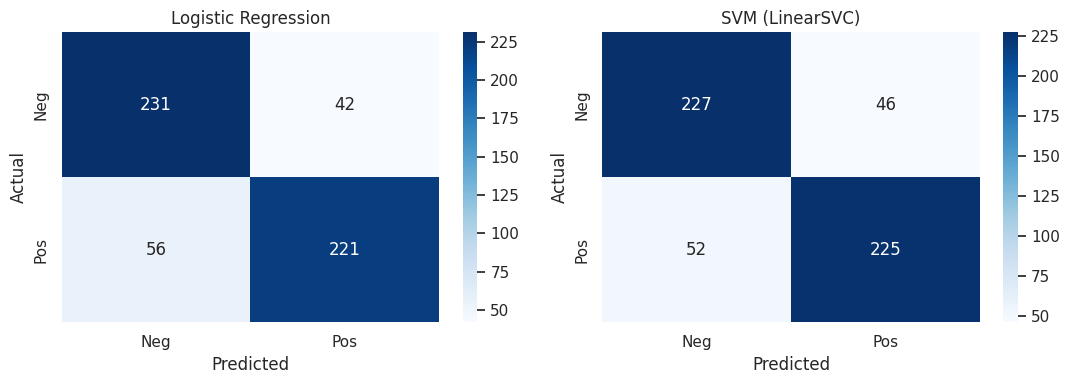

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, y_pred) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Neg', 'Pos'], yticklabels=['Neg', 'Pos'])
    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()

**Discussion:** Both models perform well above the 50% baseline using only word counts. The model with the higher F1-score is the better overall choice. Limitations of BOW: it ignores word order and context (e.g. *"not good"* vs *"good"*) and cannot understand sarcasm, which is where LLMs and transformer models improve on this approach.

## Task 8: Test the model with new sentences

In [16]:
best_name = results_df['F1'].idxmax()
best_model = models[best_name]
print('Using best model:', best_name, '\n')

def predict_sentiment(sentence, model=best_model):
    cleaned = preprocess(sentence)
    vec = bow.transform([cleaned])
    label = model.predict(vec)[0]
    return 'Positive' if label == 1 else 'Negative'

new_sentences = [
    'I absolutely love this phone, the battery life is amazing!',
    'The food was cold and the service was terrible.',
    'This movie was a complete waste of time.',
    'Great quality and very fast delivery.',
    'I would never buy this product again.',
]

for s in new_sentences:
    print(f'{predict_sentiment(s):9s} | {s}')

Using best model: SVM (LinearSVC) 

Positive  | I absolutely love this phone, the battery life is amazing!
Negative  | The food was cold and the service was terrible.
Negative  | This movie was a complete waste of time.
Positive  | Great quality and very fast delivery.
Negative  | I would never buy this product again.


In [17]:
# Try your own sentence
my_sentence = 'The staff were friendly and the room was clean.'
print(predict_sentiment(my_sentence), '|', my_sentence)

Positive | The staff were friendly and the room was clean.
